## Tutorial: compute C_ell^yy and its gradients with the JAX pipeline.

Three parts:
  1. Compute C_ell^yy (1-halo + 2-halo) with the Arnaud 2010 and Battaglia 2012 profiles
  2. Take gradients w.r.t. cosmological parameters
  3. Take gradients w.r.t. pressure-profile parameters

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
})
import warnings; warnings.filterwarnings('ignore')
import os; os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time

import jax; jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np

from classy_szfast.differentiable import (
    CosmoParams,
    ProfileParamsA10,
    cl_yy_from_params,
)

## 1. Forward pass — compute C_ell^yy


In [3]:
cosmo = CosmoParams(
    omega_b    = 0.02242,
    omega_cdm  = 0.11933,
    H0         = 67.66,
    tau_reio   = 0.0561,
    ln10_10_As = 3.047,
    n_s        = 0.9665,
)


# Arnaud 2010 profile (defaults — you can change these)
profile = ProfileParamsA10()

In [4]:
profile

ProfileParamsA10(P0=8.13, c500=1.156, gamma=0.3292, alpha=1.062, beta=5.4807)

In [5]:
# Multipole range
ell = jnp.geomspace(2, 5000, 80)

# Compute
t0 = time.perf_counter()
cl_1h, cl_2h = cl_yy_from_params(
    ell, cosmo,
    profile_params=profile,
    profile='arnaud10',
    delta_crit=500.0,
    n_z=100,
    n_m=200,
)
dt = time.perf_counter() - t0

# Convert to D_ell × 10^12 for plotting
dl_fac = ell * (ell + 1) / (2 * jnp.pi) * 1e12
dl_1h = dl_fac * cl_1h
dl_2h = dl_fac * cl_2h

print(f"  Time:      {dt*1e3:.0f} ms")
print(f"  ell range: [{float(ell[0]):.0f}, {float(ell[-1]):.0f}]")
print(f"  D_ell 1h:  [{float(dl_1h.min()):.3e}, {float(dl_1h.max()):.3e}]")
print(f"  D_ell 2h:  [{float(dl_2h.min()):.3e}, {float(dl_2h.max()):.3e}]")


  Time:      3396 ms
  ell range: [2, 5000]
  D_ell 1h:  [7.036e-04, 2.603e+00]
  D_ell 2h:  [6.100e-04, 2.986e-02]


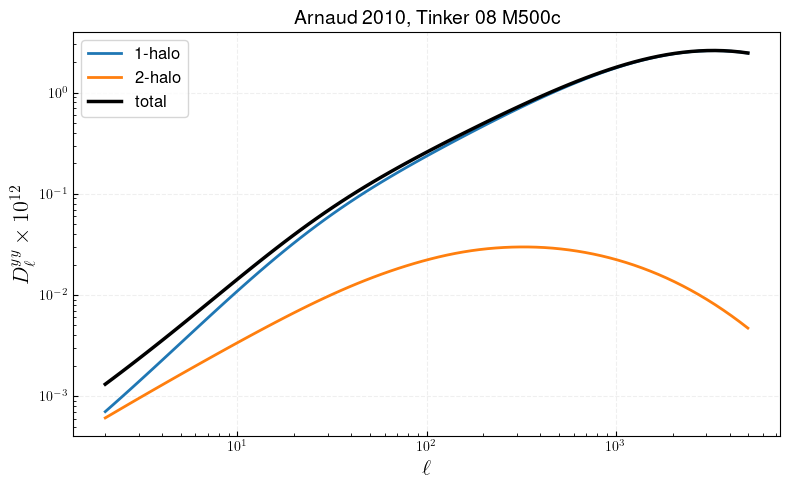

In [6]:

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ell, dl_1h, 'C0-', lw=2, label='1-halo')
ax.loglog(ell, dl_2h, 'C1-', lw=2, label='2-halo')                                                                                                                                                                                                 
ax.loglog(ell, dl_1h + dl_2h, 'k-', lw=2.5, label='total')
ax.set_xlabel(r"$\ell$", fontsize=16)                                                                                                                                                                                                              
ax.set_ylabel(r"$D_\ell^{yy} \times 10^{12}$", fontsize=16)
ax.set_title("Arnaud 2010, Tinker 08 M500c", fontsize=14)
ax.legend(fontsize=12)
ax.grid(alpha=0.2, ls='--')
ax.tick_params(direction='in', which='both')
plt.tight_layout()
plt.show()



### Throughput benchmark                                                                                                                                                                     


In [7]:
N = 200                                
rng = np.random.default_rng(42)                                                                                                                                                                                                                    
                                                        
times_fwd = []                                                                                                                                                                                                                                     
for i in range(N):                                        
  c = CosmoParams(
      omega_b    = rng.uniform(0.019, 0.025),
      omega_cdm  = rng.uniform(0.10, 0.14),
      H0         = rng.uniform(60.0, 80.0),
      tau_reio   = rng.uniform(0.04, 0.08),
      ln10_10_As = rng.uniform(2.9, 3.2),
      n_s        = rng.uniform(0.92, 1.01),
  )
  p = ProfileParamsA10(
      P0    = rng.uniform(5.0, 12.0),
      c500  = rng.uniform(0.8, 1.6),
      gamma = rng.uniform(0.1, 0.6),
      alpha = rng.uniform(0.8, 1.4),
      beta  = rng.uniform(4.0, 7.0),
  )
  t0 = time.perf_counter()
  cl1, cl2 = cl_yy_from_params(ell, c, profile_params=p,
                                profile='arnaud10', delta_crit=500.0)
  cl1.block_until_ready()
  dt = time.perf_counter() - t0
  times_fwd.append(dt * 1e3)

times_fwd = np.array(times_fwd)
print(f"Forward: {times_fwd.mean():.1f} ± {times_fwd.std():.1f} ms/eval  "
    f"({1e3/times_fwd.mean():.0f} evals/s)")

Forward: 28.3 ± 1.1 ms/eval  (35 evals/s)


**Battaglia**

In [8]:
from classy_szfast.differentiable import (                                                                                                                                                                                                         
  CosmoParams, ProfileParamsB12, cl_yy_from_params,
)                                                                                                                                                                                                                                                  
                                                        
cosmo = CosmoParams(
  omega_b=0.02242, omega_cdm=0.11933, H0=67.66,
  tau_reio=0.0561, ln10_10_As=3.047, n_s=0.9665,
)

# Battaglia 2012: P0(M,z) = P0_A × (M/1e14)^P0_am × (1+z)^P0_az, etc.
profile = ProfileParamsB12()   # defaults = B12 Table 1
# profile = ProfileParamsB12(P0_A=20.0, beta_az=0.5)  # override some

ell = jnp.geomspace(2, 5000, 80)

cl_1h, cl_2h = cl_yy_from_params(
  ell, cosmo, profile_params=profile,
  profile='battaglia12', delta_crit=200.0,
)

dl_fac = ell * (ell + 1) / (2 * jnp.pi) * 1e12
dl_1h = dl_fac * cl_1h
dl_2h = dl_fac * cl_2h

# Gradients w.r.t. all 9 B12 fitting coefficients + 7 cosmo params
def loss(c, p):
  cl1, cl2 = cl_yy_from_params(ell, c, profile_params=p,
                                profile='battaglia12', delta_crit=200.0)
  return jnp.sum(cl1 + cl2)

g_cosmo, g_profile = jax.grad(loss, argnums=(0, 1))(cosmo, profile)

for name, g in g_profile._asdict().items():
  print(f"  d(loss)/d({name:>8s}) = {float(g):+.4e}")

  d(loss)/d(    P0_A) = +1.7999e-15
  d(loss)/d(   P0_am) = +5.6406e-14
  d(loss)/d(   P0_az) = +1.8570e-15
  d(loss)/d(    xc_A) = +1.8915e-13
  d(loss)/d(   xc_am) = +1.6065e-13
  d(loss)/d(   xc_az) = +5.4789e-15
  d(loss)/d(  beta_A) = -3.2589e-14
  d(loss)/d( beta_am) = -2.2916e-13
  d(loss)/d( beta_az) = -8.1822e-15


In [9]:
N = 200    
rng = np.random.default_rng(42)
                                                                                                                                                                                                                                                 
times_fwd = []
for i in range(N):                                                                                                                                                                                                                                 
  c = CosmoParams(                                      
      omega_b    = rng.uniform(0.019, 0.025),
      omega_cdm  = rng.uniform(0.10, 0.14),
      H0         = rng.uniform(60.0, 80.0),
      tau_reio   = rng.uniform(0.04, 0.08),
      ln10_10_As = rng.uniform(2.9, 3.2),
      n_s        = rng.uniform(0.92, 1.01),
  )
  p = ProfileParamsB12(
      P0_A    = rng.uniform(10.0, 25.0),
      P0_am   = rng.uniform(0.05, 0.3),
      P0_az   = rng.uniform(-1.0, -0.5),
      xc_A    = rng.uniform(0.3, 0.7),
      xc_am   = rng.uniform(-0.05, 0.05),
      xc_az   = rng.uniform(0.4, 1.0),
      beta_A  = rng.uniform(3.0, 6.0),
      beta_am = rng.uniform(0.01, 0.08),
      beta_az = rng.uniform(0.2, 0.6),
  )
  t0 = time.perf_counter()
  cl1, cl2 = cl_yy_from_params(ell, c, profile_params=p,
                                profile='battaglia12', delta_crit=200.0)
  cl1.block_until_ready()
  dt = time.perf_counter() - t0
  times_fwd.append(dt * 1e3)

times_fwd = np.array(times_fwd)
print(f"Forward: {times_fwd.mean():.1f} ± {times_fwd.std():.1f} ms/eval  "
    f"({1e3/times_fwd.mean():.0f} evals/s)")

Forward: 45.0 ± 2.9 ms/eval  (22 evals/s)


## 2. Gradients w.r.t. cosmological parameters

In [11]:
def loss_cosmo(c):
    """Scalar loss = sum of C_ell (1h + 2h)."""
    cl_1h, cl_2h = cl_yy_from_params(
        ell, c, profile_params=profile,
        profile='arnaud10', delta_crit=500.0,
    )
    return jnp.sum(cl_1h + cl_2h)

t0 = time.perf_counter()
grads_cosmo = jax.grad(loss_cosmo)(cosmo)
dt = time.perf_counter() - t0
print(f"  jax.grad time: {dt:.1f} s")

for name, val, g in zip(cosmo._fields, cosmo, grads_cosmo):
    print(f"  d(loss)/d({name:>14s}) = {float(g):+12.4e}   (value={float(val)})")


  jax.grad time: 4.6 s
  d(loss)/d(       omega_b) =  -1.1783e-12   (value=0.02242)
  d(loss)/d(     omega_cdm) =  +2.3832e-12   (value=0.11933)
  d(loss)/d(            H0) =  -3.5062e-15   (value=67.66)
  d(loss)/d(      tau_reio) =  +0.0000e+00   (value=0.0561)
  d(loss)/d(    ln10_10_As) =  +1.4431e-13   (value=3.047)
  d(loss)/d(           n_s) =  +7.2378e-14   (value=0.9665)
  d(loss)/d(        m_ncdm) =  +1.1536e-14   (value=0.06)


## 3. Gradients w.r.t. Arnaud 2010 profile parameters

In [10]:
def loss_profile(pp):
    """Scalar loss = sum of C_ell^1h (most sensitive to profile)."""
    cl_1h, _ = cl_yy_from_params(
        ell, cosmo, profile_params=pp,
        profile='arnaud10', delta_crit=500.0,
    )
    return jnp.sum(cl_1h)

t0 = time.perf_counter()
grads_profile = jax.grad(loss_profile)(profile)
dt = time.perf_counter() - t0
print(f"  jax.grad time: {dt:.1f} s")

for name, val, g in zip(profile._fields, profile, grads_profile):
    print(f"  d(loss)/d({name:>5s}) = {float(g):+12.4e}   (default={float(val)})")


  jax.grad time: 0.1 s
  d(loss)/d( P0_A) =  +0.0000e+00   (default=18.1)
  d(loss)/d(P0_am) =  +0.0000e+00   (default=0.154)
  d(loss)/d(P0_az) =  +0.0000e+00   (default=-0.758)
  d(loss)/d( xc_A) =  +0.0000e+00   (default=0.497)
  d(loss)/d(xc_am) =  +0.0000e+00   (default=-0.00865)
  d(loss)/d(xc_az) =  +0.0000e+00   (default=0.731)
  d(loss)/d(beta_A) =  +0.0000e+00   (default=4.35)
  d(loss)/d(beta_am) =  +0.0000e+00   (default=0.0393)
  d(loss)/d(beta_az) =  +0.0000e+00   (default=0.415)


## 4. Parameter sweep

Vary one parameter and plot the response

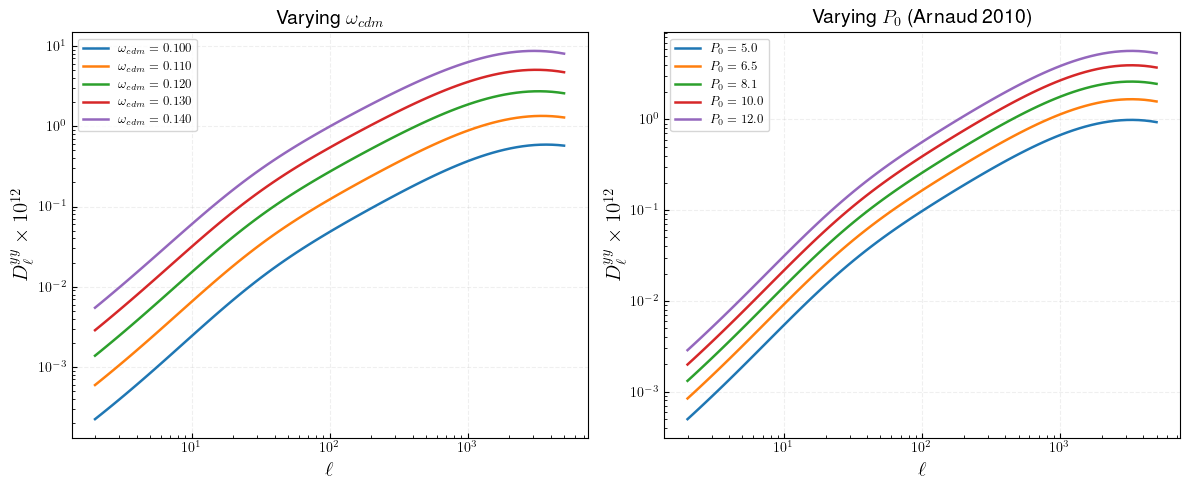

In [16]:
omega_cdm_vals = jnp.linspace(0.10, 0.14, 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for omega_cdm in omega_cdm_vals:
    c = cosmo._replace(omega_cdm=float(omega_cdm))
    cl1, cl2 = cl_yy_from_params(
        ell, c, profile_params=profile,
        profile='arnaud10', delta_crit=500.0,
    )
    dl_tot = dl_fac * (cl1 + cl2)
    label = rf"$\omega_{{cdm}}={float(omega_cdm):.3f}$"
    axes[0].loglog(ell, dl_tot, lw=1.8, label=label)

axes[0].set_xlabel(r"$\ell$", fontsize=15)
axes[0].set_ylabel(r"$D_\ell^{yy} \times 10^{12}$", fontsize=15)
axes[0].set_title(r"Varying $\omega_{cdm}$", fontsize=14)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.2, ls='--')

# Also vary P0
P0_vals = jnp.array([5.0, 6.5, 8.13, 10.0, 12.0])
for P0 in P0_vals:
    pp = ProfileParamsA10(P0=float(P0))
    cl1, cl2 = cl_yy_from_params(
        ell, cosmo, profile_params=pp,
        profile='arnaud10', delta_crit=500.0,
    )
    dl_tot = dl_fac * (cl1 + cl2)
    label = rf"$P_0={float(P0):.1f}$"
    axes[1].loglog(ell, dl_tot, lw=1.8, label=label)

axes[1].set_xlabel(r"$\ell$", fontsize=15)
axes[1].set_ylabel(r"$D_\ell^{yy} \times 10^{12}$", fontsize=15)
axes[1].set_title(r"Varying $P_0$ (Arnaud 2010)", fontsize=14)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.2, ls='--')

for ax in axes:
    ax.tick_params(direction='in', which='both')

plt.tight_layout()